# Dataset explorer

A quick visual tour of `data/surfaces.npz`, the dataset of rough Bergomi implied volatility surfaces used to train the network (built by `scripts/02_generate_dataset.py`).

Each sample is a parameter vector $\theta = (H, \eta, \rho, \xi_0)$ and its Monte Carlo implied volatility surface on a fixed $8 \times 10$ grid of maturities $T$ and scaled log-moneyness $m = \log(K/S_0)/\sqrt{T}$, together with the Monte Carlo standard error of every point.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

from rbergomi_nn.dataset import SPLITS, TRAIN_BOX, SurfaceDataset

ROOT = Path.cwd().parent if Path.cwd().name == "docs" else Path.cwd()
ds = SurfaceDataset.load(ROOT / "data" / "surfaces.npz")

plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
NAMES = ["H", "eta", "rho", "xi0"]
LABELS = ["$H$", r"$\eta$", r"$\rho$", r"$\xi_0$"]
COLOURS = {"train": "tab:blue", "val": "tab:purple", "test": "tab:green", "gap": "tab:orange", "ood": "tab:red"}

T = np.array(ds.grid.maturities)            # (8,)
m = np.array(ds.grid.scaled_moneyness)      # (10,)
k = ds.grid.log_moneyness.numpy()           # log(K / S0), shape (8, 10)
ATM = int(np.where(m == 0)[0][0])

print(f"{len(ds)} surfaces on a {len(T)} x {len(m)} grid (maturity x strike)")
print(f"Monte Carlo: {ds.mc.n_paths:,} paths per surface, {ds.mc.steps_per_year} time steps per year")
print(f"undefined implied vols: {np.isnan(ds.implied_vol).sum()}")
pd.Series(ds.split).value_counts().reindex(SPLITS).rename("surfaces").to_frame().T

18111 surfaces on a 8 x 10 grid (maturity x strike)
Monte Carlo: 16,384 paths per surface, 200 time steps per year
undefined implied vols: 0


,train,val,test,gap,ood
surfaces,11233,1376,1433,2342,1727


## The data as a table

One row per surface: the four parameters, the 80 implied vols, their 80 standard errors and the split. Below, the range of each parameter in each split.

In [2]:
iv_columns = [f"iv[T={t}, m={x:+.2f}]" for t in T for x in m]
df = pd.concat([
    pd.DataFrame(ds.theta, columns=NAMES),
    pd.DataFrame(ds.flat_implied_vol, columns=iv_columns),
    pd.DataFrame(ds.implied_vol_stderr.reshape(len(ds), -1), columns=[c.replace("iv", "stderr") for c in iv_columns]),
    pd.Series(ds.split, name="split"),
], axis=1)
display(df)
display(df.groupby("split")[NAMES].agg(["min", "max"]).loc[list(SPLITS)].round(3))

,H,eta,rho,xi0,"iv[T=0.1, m=-0.30]","iv[T=0.1, m=-0.25]","iv[T=0.1, m=-0.20]","iv[T=0.1, m=-0.15]","iv[T=0.1, m=-0.10]","iv[T=0.1, m=-0.05]",...,"stderr[T=2.0, m=-0.25]","stderr[T=2.0, m=-0.20]","stderr[T=2.0, m=-0.15]","stderr[T=2.0, m=-0.10]","stderr[T=2.0, m=-0.05]","stderr[T=2.0, m=+0.00]","stderr[T=2.0, m=+0.05]","stderr[T=2.0, m=+0.10]","stderr[T=2.0, m=+0.15]",split
0,0.351915,1.502431,-0.881303,0.061557,0.281222,0.274471,0.267585,0.260573,0.253454,0.246250,...,0.001299,0.001165,0.001039,0.000920,0.000807,0.000691,0.000560,0.000405,0.000244,train
1,0.156732,2.297796,-0.347394,0.103480,0.338518,0.328524,0.318881,0.309730,0.301250,0.293657,...,0.000792,0.000720,0.000654,0.000595,0.000550,0.000526,0.000519,0.000525,0.000544,train
2,0.100060,1.175046,-0.695520,0.030784,0.211079,0.203969,0.196847,0.189735,0.182659,0.175658,...,0.000919,0.000815,0.000719,0.000627,0.000536,0.000444,0.000354,0.000274,0.000214,train
3,0.299303,2.876660,-0.533519,0.084179,0.320340,0.309495,0.298772,0.288250,0.278037,0.268283,...,0.000653,0.000548,0.000454,0.000375,0.000311,0.000274,0.000276,0.000298,0.000336,train
4,0.268450,1.354481,-0.244193,0.080462,0.295367,0.291574,0.288005,0.284689,0.281654,0.278928,...,0.000406,0.000338,0.000276,0.000226,0.000197,0.000192,0.000203,0.000215,0.000225,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18106,0.360605,1.220469,-0.339914,0.181798,0.434349,0.431597,0.428934,0.426366,0.423896,0.421531,...,0.000517,0.000436,0.000357,0.000284,0.000223,0.000183,0.000173,0.000187,0.000212,ood
18107,0.072810,3.891666,-0.929348,0.026856,0.208593,0.191078,0.172972,0.154158,0.134593,0.114780,...,0.001822,0.001609,0.001402,0.001205,0.001032,0.000936,0.001146,0.001590,0.002138,ood
18108,0.082285,0.551516,-0.598998,0.043909,0.226170,0.223106,0.220062,0.217045,0.214065,0.211131,...,0.000736,0.000693,0.000650,0.000606,0.000561,0.000516,0.000469,0.000423,0.000378,ood
18109,0.276364,3.335503,-0.208492,0.173651,0.404954,0.395769,0.387194,0.379380,0.372500,0.366728,...,0.000759,0.000720,0.000684,0.000651,0.000625,0.000617,0.000633,0.000670,0.000723,ood


H          eta          rho        xi0      
        min   max    min    max   min  max   min   max
split                                                 
train  0.05  0.40  1.000  3.000 -0.90 -0.2  0.02  0.12
val    0.05  0.40  1.001  2.999 -0.90 -0.2  0.02  0.12
test   0.05  0.40  1.002  2.999 -0.90 -0.2  0.02  0.12
gap    0.20  0.25  1.000  3.000 -0.90 -0.2  0.02  0.12
ood    0.02  0.50  0.501  3.999 -0.98 -0.0  0.01  0.20

## One surface

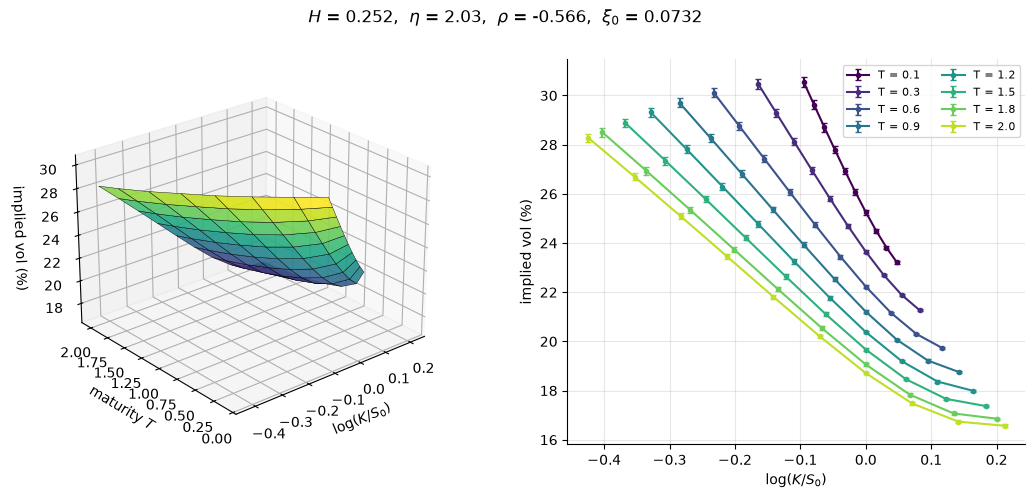

In [6]:
train_idx = np.where(ds.split == "train")[0]
i = train_idx[np.argmin(np.linalg.norm(TRAIN_BOX.normalise(ds.theta[train_idx]), axis=1))]
iv, se = 100 * ds.implied_vol[i], 100 * ds.implied_vol_stderr[i]
title = ",  ".join(f"{l} = {v:.3g}" for l, v in zip(LABELS, ds.theta[i]))

fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(k, np.repeat(T[:, None], len(m), axis=1), iv, cmap="viridis", edgecolor="k", lw=0.3, alpha=0.9)
ax.set(xlabel=r"$\log(K/S_0)$", ylabel="maturity $T$", zlabel="implied vol (%)")
ax.view_init(elev=25, azim=-130)

ax = fig.add_subplot(1, 2, 2)
colours = plt.cm.viridis(np.linspace(0, 0.9, len(T)))
for row, (t, c) in enumerate(zip(T, colours)):
    ax.errorbar(k[row], iv[row], yerr=2 * se[row], fmt="o-", ms=3, capsize=2, color=c, label=f"T = {t}")
ax.set(xlabel=r"$\log(K/S_0)$", ylabel="implied vol (%)")
ax.legend(fontsize=8, ncol=2)
fig.suptitle(title)
plt.show()

## The signature of rough volatility: the ATM skew

The at-the-money skew $\partial \sigma / \partial \log K$ (central difference around the money) against maturity, in log-log scale. Rough Bergomi predicts that it explodes at short maturities like a power law, $|\text{skew}(T)| \propto T^{H - 1/2}$: the rougher the variance, the steeper the line. Four surfaces with similar $\eta \approx 2$ and $\rho \approx -0.7$ isolate the effect of $H$; dashed lines are power-law fits on the four shortest maturities.

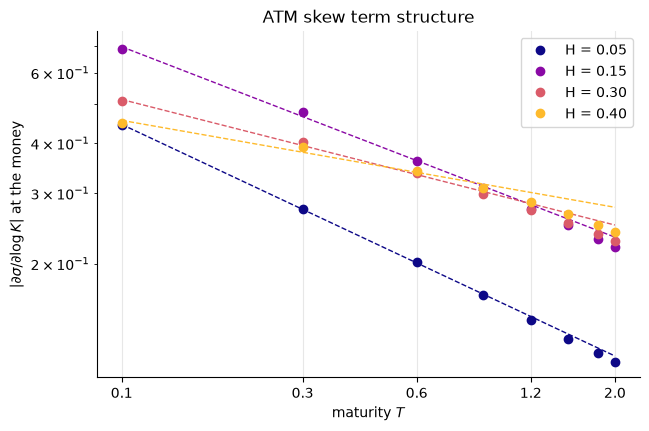

,H,theory H - 1/2,fitted slope
0,0.050,-0.450,-0.445
1,0.147,-0.353,-0.366
2,0.302,-0.198,-0.241
3,0.400,-0.100,-0.167


In [8]:
iv_all, theta = ds.implied_vol, ds.theta
dk = k[:, ATM + 1] - k[:, ATM - 1]                                  # (8,) strike step at each maturity
skew = (iv_all[:, :, ATM + 1] - iv_all[:, :, ATM - 1]) / dk         # (N, 8)

# four surfaces with different H but similar eta and rho
idx = np.where((ds.split == "train") & (np.abs(theta[:, 1] - 2.0) < 0.2) & (np.abs(theta[:, 2] + 0.7) < 0.1))[0]
idx = idx[np.argsort(theta[idx, 0])]
idx = idx[np.linspace(0, len(idx) - 1, 4).astype(int)]

fig, ax = plt.subplots(figsize=(7, 4.5))
rows = []
for i, c in zip(idx, plt.cm.plasma(np.linspace(0, 0.85, len(idx)))):
    slope, intercept = np.polyfit(np.log(T[:4]), np.log(-skew[i, :4]), 1)
    ax.loglog(T, -skew[i], "o", color=c, label=f"H = {theta[i, 0]:.2f}")
    ax.loglog(T, np.exp(intercept) * T**slope, "--", color=c, lw=1)
    rows.append({"H": round(theta[i, 0], 3), "theory H - 1/2": round(theta[i, 0] - 0.5, 3),
                 "fitted slope": round(slope, 3)})
ticks = [0.1, 0.3, 0.6, 1.2, 2.0]
ax.set_xticks(ticks, [str(t) for t in ticks])
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set(xlabel="maturity $T$", ylabel=r"$|\partial \sigma / \partial \log K|$ at the money",
       title="ATM skew term structure")
ax.legend()
plt.show()
pd.DataFrame(rows)

## The whole dataset at a glance

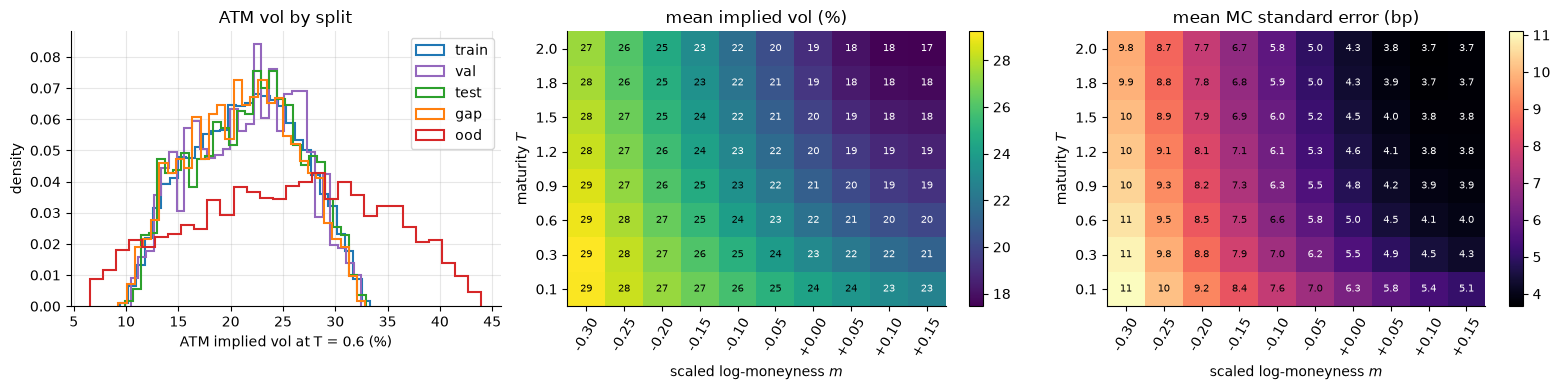

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
row = list(T).index(0.6)
for s in SPLITS:
    axes[0].hist(100 * ds.implied_vol[ds.split == s, row, ATM], bins=30, density=True,
                 histtype="step", lw=1.5, color=COLOURS[s], label=s)
axes[0].set(xlabel=f"ATM implied vol at T = {T[row]} (%)", ylabel="density", title="ATM vol by split")
axes[0].legend()

panels = [(100 * ds.implied_vol.mean(axis=0), "mean implied vol (%)", "viridis"),
          (1e4 * ds.implied_vol_stderr.mean(axis=0), "mean MC standard error (bp)", "magma")]
for ax, (values, title, cmap) in zip(axes[1:], panels):
    image = ax.imshow(values, origin="lower", aspect="auto", cmap=cmap)
    for (r, c), v in np.ndenumerate(values):
        ax.text(c, r, f"{v:.0f}" if v >= 10 else f"{v:.1f}", ha="center", va="center", fontsize=7,
                color="w" if v < values.mean() else "k")
    ax.set_xticks(range(len(m)), [f"{x:+.2f}" for x in m], rotation=60)
    ax.set_yticks(range(len(T)), [str(t) for t in T])
    ax.set(xlabel="scaled log-moneyness $m$", ylabel="maturity $T$", title=title)
    ax.grid(False)
    fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()